# Cluster cohorts → Bray-Curtis (day 0 → last day), bacteria only

For each subject: Bray-Curtis dissimilarity between its **day 0** and **last day** bacterial
communities (species level, relative abundance), summarised as one box plot per cluster.

Built on domain libraries rather than hand-rolled code:

| Step | Library |
|---|---|
| Taxonomy / lineage (handles merged tax_ids) | `ete3.NCBITaxa` |
| Counts, roll-up to rank, relative abundance | `biom.Table` (`collapse`, `norm`) |
| Bray-Curtis | `skbio.diversity.beta_diversity` |
| Plot | `seaborn` |

In [1]:
import sys
from pathlib import Path

ROOT = Path("/Users/yarintamam/Code/Ask-SLM")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))  # repo has no packaging; make it importable (see Tests/conftest.py)

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from biom import Table
from ete3 import NCBITaxa
from skbio.diversity import beta_diversity

from askslm import metadata, taxonomy

INPUTS = ROOT / "Workspaces/ABX/inputs"
CANON = INPUTS / "Supplementary/canon.xlsx"
MASTER_MAP = ROOT / "Notebooks/Viral_Ecological_Clusters_Master_Map-v2.xlsx"
OUT = ROOT / "Notebooks/out/braycurtis"
OUT.mkdir(parents=True, exist_ok=True)

# the two knobs that define the community: which kingdom, and at which rank
DOMAIN_TAXID = 2             # 2 Bacteria | 2157 Archaea | 2759 Eukaryota | 10239 Viruses
RANK = "species"             # rank to roll the atomic counts up to
BASELINE_TOLERANCE_DAYS = 2  # accept the nearest sample as a day-0 proxy within +/- this

## Cohort (sample metadata)

WGS samples of clustered subjects, with `day` from `canon.xlsx` and cluster from the Master Map.
Inner joins keep only subjects that are both clustered and have a day. This frame becomes the
**sample metadata** attached to the community table in the next step.

In [2]:
samples = metadata.extract(str(INPUTS / "metadata.csv"))
clusters = pd.read_excel(MASTER_MAP)                  # Subject, Cluster_ID, Cluster_Name
days = pd.read_excel(CANON)[["library", "day"]]

cohort = (
    samples.query("assay_type == 'WGS'")
    .merge(clusters, left_on="host_subject_id_sam", right_on="Subject")
    .merge(days, left_on="sample_name", right_on="library")
    .loc[:, ["acc", "host_subject_id_sam", "day", "Cluster_ID", "Cluster_Name"]]  # .loc[rows, cols]: ":" = all rows, list = keep just these columns

)
cohort["Cluster_ID"] = cohort["Cluster_ID"].astype(int)

## Assemble one community object (`biom.Table`)

A *community* is **one object** made of four aligned parts — the model behind phyloseq, QIIME 2 and
`TreeSummarizedExperiment`:

| Part | Here |
|---|---|
| **observations** (rows) | features / taxa — tax_ids, rolled up to `RANK` |
| **samples** (columns) | sequencing runs (`acc`) |
| **observation metadata** | taxonomy per feature — in the chosen kingdom? which `RANK`-taxon? |
| **sample metadata** | the cohort — subject, day, cluster |

Build each part, attach it by id with `add_metadata`, then do **every transform on the object**:
`filter` the kingdom → `collapse` to the rank → `filter` cohort → `norm`. Source-agnostic — any input
with per-taxon counts plus a taxonomy fits, and `DOMAIN_TAXID` / `RANK` are the only two knobs.

In [3]:
# A community is ONE biom.Table = counts + observation metadata + sample metadata
# (the phyloseq / QIIME 2 / TreeSummarizedExperiment model). Build each part, attach, transform.

# OBSERVATIONS (taxa) x SAMPLES -- the count matrix. self_count = reads assigned directly to a taxon.
counts = (taxonomy.load(str(INPUTS / "taxonomy.csv"))
          .pivot_table(index="tax_id", columns="acc", values="self_count", aggfunc="sum", fill_value=0))

# OBSERVATION METADATA -- lineage per taxon, from the single taxonomy authority (ete3; translates merges).
ncbi = NCBITaxa()
domain = ncbi.get_taxid_translator([DOMAIN_TAXID])[DOMAIN_TAXID]   # e.g. "Bacteria"
lineage = ncbi.get_lineage_translator(counts.index.tolist())
rank_of = ncbi.get_rank(list({anc for lin in lineage.values() for anc in lin}))
def ancestor_at_rank(tax_id):
    return next((anc for anc in lineage.get(tax_id, []) if rank_of.get(anc) == RANK), None)


observation_metadata = {str(t): {"in_domain": DOMAIN_TAXID in lineage.get(t, []),
                                 "rank_taxon": ancestor_at_rank(t)} for t in counts.index}

# SAMPLE METADATA -- the cohort, one row per sample.
sample_metadata = cohort.set_index("acc").to_dict("index")

# ASSEMBLE the one object, then transform it -- every step is a method on the table.
community = Table(counts.values, observation_ids=counts.index.astype(str), sample_ids=counts.columns.astype(str))
community.add_metadata(observation_metadata, axis="observation")
community.add_metadata(sample_metadata, axis="sample")
community = (
    community
    .filter(lambda v, i, md: md["in_domain"] and md["rank_taxon"], axis="observation", inplace=False)  # keep the chosen kingdom, with a RANK-taxon
    .collapse(lambda i, md: str(md["rank_taxon"]), norm=False, axis="observation", include_collapsed_metadata=False)  # roll counts up to RANK
    .filter(lambda v, i, md: "Cluster_Name" in md, axis="sample", inplace=False)  # keep cohort samples
    .norm(axis="sample", inplace=False)                                           # relative abundance
)
print(f"community: {community.shape[0]} {domain} {RANK} x {community.shape[1]} cohort samples")

community: 12933 Bacteria species x 960 cohort samples


## Bray-Curtis: day 0 → last day, per subject

Sample metadata lives on the community table, so we read it back to pick each subject's baseline and
last sample, subset the table to that pair, and let `skbio` compute Bray-Curtis on it directly.
Baseline is the `day == 0` sample, or the nearest within `BASELINE_TOLERANCE_DAYS`; subjects with no
acceptable baseline or fewer than two timepoints are skipped.

In [4]:
def baseline_and_last(subject_samples: pd.DataFrame):
    """(baseline_row, last_row), or None if no day-0 sample within tolerance."""
    s = subject_samples.sort_values("day")
    exact = s[s["day"] == 0]
    baseline = exact.iloc[0] if len(exact) else s.iloc[s["day"].abs().argmin()]
    if abs(baseline["day"]) > BASELINE_TOLERANCE_DAYS:
        return None
    return baseline, s.iloc[-1]


# pull the sample metadata back off the table to drive the day-0 -> last selection
sample_meta = pd.DataFrame(list(community.metadata(axis="sample")), index=community.ids("sample"))

records = []
for subject, subject_samples in sample_meta.groupby("host_subject_id_sam"):
    if subject_samples["day"].nunique() < 2:
        continue
    pair = baseline_and_last(subject_samples)
    if pair is None:
        continue
    baseline, last = pair
    pair_table = community.filter([baseline.name, last.name], axis="sample", inplace=False)
    distance = beta_diversity("braycurtis", pair_table)[baseline.name, last.name]
    records.append({
        "subject": subject, "Cluster_ID": int(baseline.Cluster_ID), "Cluster_Name": baseline.Cluster_Name,
        "day0": int(baseline.day), "last_day": int(last.day), "braycurtis": float(distance),
    })

braycurtis = pd.DataFrame(records).sort_values(["Cluster_ID", "subject"]).reset_index(drop=True)
braycurtis.to_csv(OUT / "braycurtis_day0_to_last.csv", index=False)
braycurtis.groupby("Cluster_Name")["braycurtis"].agg(["size", "mean"])

,size,mean
Cluster_Name,,
Cluster 0: Depletion (Standard Crash),27,0.412113
Cluster 1: Bloomers (Typically Post-ABX),8,0.376979
Cluster 2: Reduction and Bloom (Secondary Succession / Opportunists),13,0.325285
Cluster 3: Bloom then Crash (Prophage Induction),11,0.332539


## One box plot per cluster

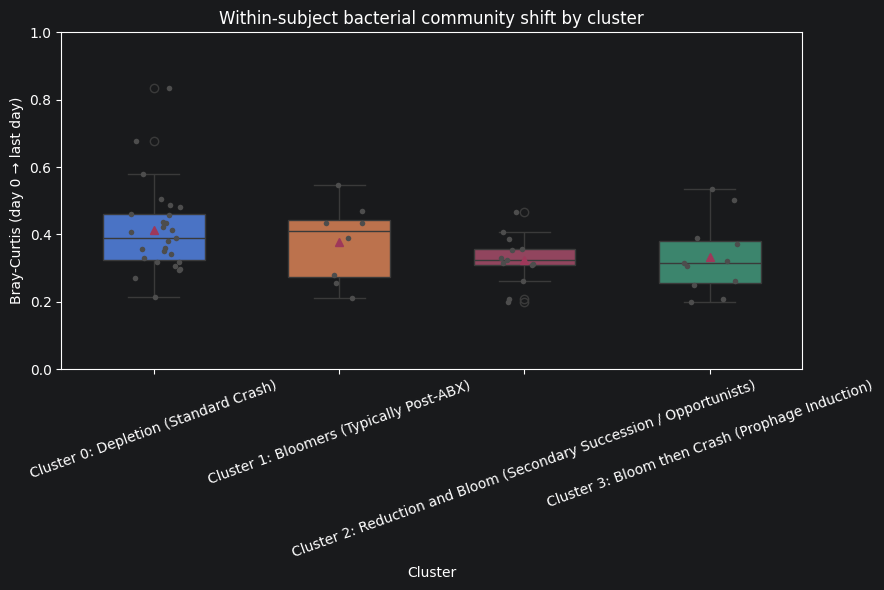

In [5]:
order = braycurtis.sort_values("Cluster_ID")["Cluster_Name"].unique()

plt.figure(figsize=(9, 6))
ax = sns.boxplot(braycurtis, x="Cluster_Name", y="braycurtis", order=order,
                 hue="Cluster_Name", legend=False, showmeans=True, width=0.55)
sns.stripplot(braycurtis, x="Cluster_Name", y="braycurtis", order=order,
              color="0.3", size=4, jitter=0.15, ax=ax)
ax.set(xlabel="Cluster", ylabel="Bray-Curtis (day 0 → last day)", ylim=(0, 1),
       title="Within-subject bacterial community shift by cluster")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(OUT / "braycurtis_boxplots.png", dpi=200, bbox_inches="tight")